# Курсовая. Проверка итогового промпта

Луценко Вячеслав Александрович, М092501(77). Тема 1. Qwen3-1.7B, E5-small, те же 32 вопроса. Системные инструкции en-v2 написаны на английском, вопросы и ответы остаются на русском. Проверяю top-k=1 и top-k=3. Фильтр отдельно отклоняет несуществующие номера источников и ответы из одной ссылки. Ранние прогоны с русскими инструкциями сохранены в соседних ноутбуках и файлах результатов.

Перед повтором запустить API с Qwen3-1.7B и COURSE_PROMPT=en-v2 (настройки Docker по умолчанию) и дождаться /health. Оба итоговых опыта имеют одинаковый implementation_sha256. Ноутбук перезаписывает eval/results/final; для отдельного повторения без перезаписи архива можно вызвать coursework.eval.run с --output coursework/eval/results/repeated.

In [1]:
from pathlib import Path
import json
import sys

ROOT = next(path for path in [Path.cwd(), *Path.cwd().parents] if (path / "coursework/api.py").is_file())
sys.path.insert(0, str(ROOT))
from coursework.cli import request
from coursework.eval.run import run_experiments

print(request("http://127.0.0.1:8000/health"))
assert request("http://127.0.0.1:8000/health")["prompt_version"] == "en-v2"

{'status': 'ready', 'model': 'Qwen/Qwen3-1.7B', 'model_revision': '70d244cc86ccca08cf5af4e1e306ecf908b1ad5e', 'prompt_version': 'en-v2', 'model_params': 1720574976, 'chunks': 87, 'corpus_sha256': '1e8f78854359bef7004b0897142ac4fd25864c56eba80033f437859b4862a668', 'device': 'cpu', 'embedding_params': 117653760, 'implementation_sha256': '87d639f7c0a5ccde37f33c6abed9ee3ee9776578c0c7eb8f5ba4a8049da2cd41', 'rss_gb': 8.79519271850586}


## Данные и метрики

32 вопроса: 24 по четырём заметкам и 8 без ответа в корпусе. У каждого известного ответа есть исходный раздел и его текст. Точность проверяю по заранее записанным ключевым понятиям. Дополнительно считаю token-F1, recall раздела, долю верных отказов и время. Ошибка принятого ответа — сигнал для ручного разбора, а не доказательство галлюцинации.

In [2]:
dataset = json.loads((ROOT / "coursework/eval/dataset.json").read_text(encoding="utf-8"))
print("Всего:", len(dataset))
print("Без ответа:", sum(row["unanswerable"] for row in dataset))
for row in dataset:
    if not row["unanswerable"]:
        assert row["evidence"] in (ROOT / row["source"]).read_text(encoding="utf-8")
print("Все эталонные разделы найдены в исходных материалах")

Всего: 32
Без ответа: 8
Все эталонные разделы найдены в исходных материалах


In [3]:
summaries = run_experiments("http://127.0.0.1:8000", ROOT / "coursework/eval/results/final")
print(json.dumps(summaries, ensure_ascii=False, indent=2))

qwen3-1.7b-en-v2-k1-verified 1/32 q01: OK, 39.95с, отказ=False


qwen3-1.7b-en-v2-k1-verified 2/32 q02: OK, 19.22с, отказ=False


qwen3-1.7b-en-v2-k1-verified 3/32 q03: OK, 24.91с, отказ=False


qwen3-1.7b-en-v2-k1-verified 4/32 q04: OK, 17.85с, отказ=False


qwen3-1.7b-en-v2-k1-verified 5/32 q05: ошибка, 27.63с, отказ=False


qwen3-1.7b-en-v2-k1-verified 6/32 q06: OK, 14.01с, отказ=False


... (57 outputs left out)

qwen3-1.7b-en-v2-k3-verified 31/32 q31: OK, 6.84с, отказ=True


qwen3-1.7b-en-v2-k3-verified 32/32 q32: OK, 9.80с, отказ=True


{
  "name": "qwen3-1.7b-en-v2-k3-verified",
  "run_id": "ca10e5f739994007a421d51c49e2b754",
  "params": {
    "top_k": 3,
    "verify": true
  },
  "metrics": {
    "accuracy": 0.6875,
    "answerable_accuracy": 0.5833333333333334,
    "correct_refusal_rate": 1.0,
    "retrieval_recall": 0.875,
    "mean_token_f1": 0.1318093021570219,
    "accepted_error_rate": 0.3,
    "refusal_rate": 0.375,
    "mean_seconds": 18.35848827812424,
    "max_seconds": 57.05742649998865,
    "p95_seconds": 55.808362999989185,
    "generated_tokens": 1072
  },
  "dataset_sha256": "c5472a201141c0264f1cf3dea7831250b9880c8aa89c2e7b1ef33437702e26ca",
  "corpus_sha256": "1e8f78854359bef7004b0897142ac4fd25864c56eba80033f437859b4862a668"
}


[
  {
    "name": "qwen3-1.7b-en-v2-k1-verified",
    "run_id": "37ed0ea9ee724d1698f558a06619e173",
    "params": {
      "top_k": 1,
      "verify": true
    },
    "metrics": {
      "accuracy": 0.5625,
      "answerable_accuracy": 0.4166666666666667,
      "correct_refusal_rate": 1.0,
      "retrieval_recall": 0.7083333333333334,
      "mean_token_f1": 0.12038544599512216,
      "accepted_error_rate": 0.4444444444444444,
      "refusal_rate": 0.4375,
      "mean_seconds": 12.949722831248891,
      "max_seconds": 39.94566250000207,
      "p95_seconds": 27.628186899994034,
      "generated_tokens": 1245
    },
    "dataset_sha256": "c5472a201141c0264f1cf3dea7831250b9880c8aa89c2e7b1ef33437702e26ca",
    "corpus_sha256": "1e8f78854359bef7004b0897142ac4fd25864c56eba80033f437859b4862a668"
  },
  {
    "name": "qwen3-1.7b-en-v2-k3-verified",
    "run_id": "ca10e5f739994007a421d51c49e2b754",
    "params": {
      "top_k": 3,
      "verify": true
    },
    "metrics": {
      "accuracy": 0.6

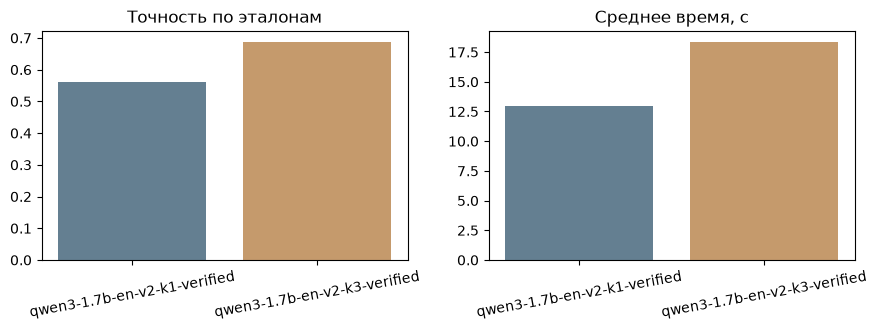

In [4]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(9, 3.4))
names = [item["name"] for item in summaries]
for axis, metric, title in zip(axes, ["accuracy", "mean_seconds"], ["Точность по эталонам", "Среднее время, с"]):
    axis.bar(names, [item["metrics"][metric] for item in summaries], color=["#647f91", "#c59a6c"])
    axis.set_title(title)
    axis.tick_params(axis="x", rotation=10)
fig.tight_layout()
fig.savefig(ROOT / "coursework/eval/results/final/comparison.png", dpi=140)
plt.show()

Второй проход той же маленькой модели не является независимым экспертом. Ошибки и отказы нужно читать в файлах результатов; сам факт ДА у проверяющего не доказывает истинность. Разбор примеров и ограничения — в README.